# Numerical mathematics: inspect accuracy, conditioning, and resolution

A numerical answer needs more context than a small residual. We will examine exact solutions, perturbations, truncation error, interpolation geometry, and adaptive differential-equation solutions through Convexity's public numerical API.

Each experiment exposes a numerical tradeoff in a table or figure. Reference formulas make errors visible; they are not pass/fail gates. NumPy builds inputs and evaluates the stated references, while Convexity performs the numerical operations under inspection. [Numerical catalog](../numerical_mathematics.md).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from convexity.math import numerical as cx

rng = np.random.default_rng(42)
plt.rcParams.update({"figure.figsize": (10, 3.8), "axes.grid": True,
                     "grid.alpha": .18, "figure.dpi": 110})

## Solve the system; inspect the decomposition

For $Ax=b$, `.value` contains the solution. Use `solve` when you need $x$ rather than forming $A^{-1}$. This symmetric positive-definite example also admits a Cholesky factorization. The lower-triangular factor exposes a different representation of the same operator.

The right-hand side is generated from a known solution. The coordinate table compares answers in solution space; a residual measures a different quantity, in equation space.

In [2]:
A = np.array([[4., 1., 0.], [1., 4., 1.], [0., 1., 3.]])
x_exact = np.array([1., -2., 3.])
b = A @ x_exact
solution = cx.solve(A, b)
display(pd.DataFrame({"exact solution": x_exact, "computed solution": solution.value,
                      "equation residual": A @ solution.value-b}))
L = cx.cholesky(A).factors["l"]
display(pd.DataFrame(L, index=["row 0", "row 1", "row 2"], columns=["column 0", "column 1", "column 2"]))
pd.DataFrame({"quantity": ["condition number", "relative residual"],
              "value": [float(cx.condition_number(A).value), cx.residual(A, solution.value, b).relative]})

,exact solution,computed solution,equation residual
0,1.0,1.0,-2.220446e-16
1,-2.0,-2.0,1.776357e-15
2,3.0,3.0,-1.776357e-15


,column 0,column 1,column 2
row 0,2.0,0.000000,0.00000
row 1,0.5,1.936492,0.00000
row 2,0.0,0.516398,1.65328


,quantity,value
0,condition number,2.387093e+00
1,relative residual,3.036061e-16


## Rank determines what can be recovered

The first least-squares system is inconsistent: no coefficient vector fits every row. The second has rank one, so infinitely many coefficient vectors fit exactly. `lstsq` returns a minimum-norm solution for the latter.

Compare rank and residual norm. A zero residual in a rank-deficient problem does not identify a unique parameter vector. The singular values reveal the absent direction.

In [3]:
C = np.array([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]])
d = np.array([1.0, 2.0, 4.0])
ls = cx.lstsq(C, d)
R = np.array([[1.0, 2.0], [2.0, 4.0], [3.0, 6.0]])
rhs = np.array([3.0, 6.0, 9.0])
rank_deficient = cx.lstsq(R, rhs)
svd = cx.svd(R)
display(pd.DataFrame({'problem': ['inconsistent', 'rank deficient'], 'rank': [ls.rank, rank_deficient.rank], 'residual norm': [ls.diagnostics.residual_norm, rank_deficient.diagnostics.residual_norm]}))

,problem,rank,residual norm
0,inconsistent,2,0.57735
1,rank deficient,1,0.00000


In [4]:
display(pd.DataFrame({"coefficient": [0, 1], "minimum-norm solution": rank_deficient.value}))
pd.DataFrame({"singular value": svd.s})

,coefficient,minimum-norm solution
0,0,0.6
1,1,1.2


,singular value
0,8.366600e+00
1,7.320183e-16


## Conditioning amplifies perturbations that a residual cannot see

Hilbert matrices become ill-conditioned as their size increases. We perturb each right-hand side along its most sensitive singular direction while keeping the relative perturbation at $10^{-10}$.

Inspect how solution change grows even when the solved equation has a tiny residual. This is a property of the inverse problem, not necessarily a solver malfunction.

In [5]:
sensitivity = []
for size in (3, 5, 7, 9):
    index = np.arange(size)
    hilbert = 1/(index[:, None]+index[None, :]+1.)
    rhs = hilbert @ np.ones(size)
    singular_vectors = cx.svd(hilbert)
    perturbation = 1e-10*np.linalg.norm(rhs)*singular_vectors.u[:, -1]
    perturbed = cx.solve(hilbert, rhs+perturbation)
    sensitivity.append({"dimension": size, "condition number": float(cx.condition_number(hilbert).value),
        "relative RHS change": np.linalg.norm(perturbation)/np.linalg.norm(rhs),
        "relative solution change": np.linalg.norm(perturbed.value-1)/np.sqrt(size),
        "relative residual": cx.residual(hilbert, perturbed.value, rhs+perturbation).relative})
pd.DataFrame(sensitivity).set_index("dimension")

,condition number,relative RHS change,relative solution change,relative residual
dimension,,,,
3,5.240568e+02,1.000000e-10,4.874721e-08,9.786038e-17
5,4.766073e+05,1.000000e-10,4.268588e-05,7.075360e-17
7,4.753674e+08,1.000000e-10,4.150856e-02,6.469910e-17
9,4.931536e+11,1.000000e-10,4.225593e+01,9.446658e-16


## Iteration budget is an accuracy choice

Solve $\cos x-x=0$. Bracketing is robust when a sign-changing interval is known; Newton's method uses a derivative and an initial point. Fixed-point iteration uses the map $x\mapsto\cos x$.

The bisection table deliberately limits iteration count and requests the partial numerical result. This makes convergence observable rather than turning it into a caught exception. A residual at a partial result is evidence of remaining error, not a successful solve.

In [6]:
f = lambda x: np.cos(x)-x
root_methods = {
    "Brent": cx.root_scalar(f, bracket=(0., 1.)),
    "Newton": cx.root_scalar(f, x0=.7, derivative=lambda x: -np.sin(x)-1,
                             tool=cx.ScalarRootSolver(method="newton")),
    "Fixed point": cx.fixed_point(np.cos, .7),
}
display(pd.DataFrame({label: {"root": float(result.value), "residual": abs(float(f(result.value))),
    "iterations": result.diagnostics.iterations} for label, result in root_methods.items()}).T)
budget_rows = []
for budget in (2, 8, 16, 40):
    result = cx.root_scalar(f, bracket=(0., 1.), tool=cx.ScalarRootSolver(method="bisect", maxiter=budget),
                            check_convergence=False)
    budget_rows.append({"iteration budget": budget, "root estimate": float(result.value),
                       "absolute residual": abs(float(f(result.value))), "converged": result.diagnostics.converged})
pd.DataFrame(budget_rows)

,root,residual,iterations
Brent,0.739085,7.993606e-15,7.0
Newton,0.739085,0.000000e+00,4.0
Fixed point,0.739085,0.000000e+00,NaN


,iteration budget,root estimate,absolute residual,converged
0,2,0.500000,3.775826e-01,False
1,8,0.738281,1.345150e-03,False
2,16,0.739075,1.744935e-05,False
3,40,0.739085,5.107836e-11,True


## Quadrature error estimates are method-dependent

Compare an endpoint singularity, an improper integral, a two-dimensional integral, and a polynomial quadrature rule. Each has an exact reference here. The returned error estimate is an algorithmic diagnostic; it is not universally a rigorous bound.

The Gauss rule integrates the stated polynomial exactly up to floating-point effects. That does not mean the same number of nodes would suffice for an oscillatory integrand or a discontinuity.

In [7]:
adaptive = cx.quad(np.sqrt, 0.0, 1.0)
improper = cx.quad(lambda x: np.exp(-x * x), -np.inf, np.inf)
multi = cx.nquad(lambda z: z[0] ** 2 + z[1] ** 2, [(0.0, 1.0), (0.0, 1.0)])
gauss = cx.gauss_quad(lambda x: x ** 6, -1.0, 1.0, n=4)
weighted = cx.integrate_density(lambda x: x * x, lambda x: np.exp(-x), 0.0, np.inf)
rows = []
for name, result, exact in [('endpoint singular derivative', adaptive, 2 / 3), ('improper Gaussian', improper, np.sqrt(np.pi)), ('two-dimensional', multi, 2 / 3), ('Gauss polynomial', gauss, 2 / 7), ('supplied density', weighted, 2.0)]:
    error = np.max(np.abs(result.value - exact))
    rows.append({'integral': name, 'value': float(result.value), 'actual error': error, 'estimated error': result.diagnostics.error_estimate})
display(pd.DataFrame(rows))

,integral,value,actual error,estimated error
0,endpoint singular derivative,0.666667,2.220446e-16,7.401486830834379e-16
1,improper Gaussian,1.772454,2.220446e-16,1.0306738724746086e-12
2,two-dimensional,0.666667,2.220446e-16,1.4754810833321613e-14
3,Gauss polynomial,0.285714,0.000000e+00,None
4,supplied density,2.000000,0.000000e+00,1.0454243942023805e-10


## Derivatives have direction and scale

For $f(x,y)=x^3+xy+y^4$, the Hessian is $\begin{pmatrix}6x&1\\1&12y^2\end{pmatrix}$. A finite-difference result and an automatic-differentiation result approximate/evaluate derivatives in different ways.

The vector-function example exposes `jvp` and `vjp`: they apply a Jacobian or its transpose without asking the caller to form the matrix. PyTorch is required for the automatic-differentiation comparison.

In [8]:
z = np.array([0.7, -0.4])
poly = lambda z: z[0] ** 3 + z[0] * z[1] + z[1] ** 4
g_exact = np.array([3 * z[0] ** 2 + z[1], z[0] + 4 * z[1] ** 3])
h_exact = np.array([[6 * z[0], 1.0], [1.0, 12 * z[1] ** 2]])
g = cx.gradient(poly, z)
h = cx.hessian(poly, z)
vector_function = lambda z: np.array([z[0] * z[1], np.sin(z[0]) + z[1] ** 2])
J_exact = np.array([[z[1], z[0]], [np.cos(z[0]), 2 * z[1]]])
J = cx.jacobian(vector_function, z)
v, w = (np.array([1.0, 2.0]), np.array([-0.5, 1.0]))
jv = cx.jvp(vector_function, z, v).value
jtw = cx.vjp(vector_function, z, w).value
display(pd.DataFrame({"analytic gradient": g_exact, "finite-difference gradient": g.value}, index=["x", "y"]))
pd.DataFrame({"entry": ["output 1 / x", "output 1 / y", "output 2 / x", "output 2 / y"],
              "analytic Jacobian": J_exact.ravel(), "finite-difference Jacobian": J.value.ravel()})

,analytic gradient,finite-difference gradient
x,1.070,1.070
y,0.444,0.444


,entry,analytic Jacobian,finite-difference Jacobian
0,output 1 / x,-0.400000,-0.400000
1,output 1 / y,0.700000,0.700000
2,output 2 / x,0.764842,0.764842
3,output 2 / y,-0.800000,-0.800000


In [9]:
automatic_hessian = cx.hessian(poly, z, tool=cx.AutoDiff()).value
display(pd.DataFrame({"entry": ["xx", "xy", "yx", "yy"], "analytic": h_exact.ravel(),
    "finite difference": h.value.ravel(), "automatic differentiation": automatic_hessian.ravel()}))
pd.DataFrame({"operation": ["J @ v", "J.T @ w"],
              "first component": [jv[0], jtw[0]], "second component": [jv[1], jtw[1]]})

,entry,analytic,finite difference,automatic differentiation
0,xx,4.20,4.20,4.20
1,xy,1.00,1.00,1.00
2,yx,1.00,1.00,1.00
3,yy,1.92,1.92,1.92


,operation,first component,second component
0,J @ v,1.000000,-0.835158
1,J.T @ w,0.964842,-1.150000


## Interpolation nodes can matter more than polynomial degree

The Runge function is smooth, yet a high-degree polynomial on equally spaced nodes can oscillate near the boundaries. Chebyshev–Lobatto nodes concentrate samples near those endpoints. A spline or PCHIP takes a local approach instead.

Compare both the curves and errors on a dense query grid. Small error at the training nodes says little about the behaviour between them. A polynomial basis change alone does not remedy poor sample placement.

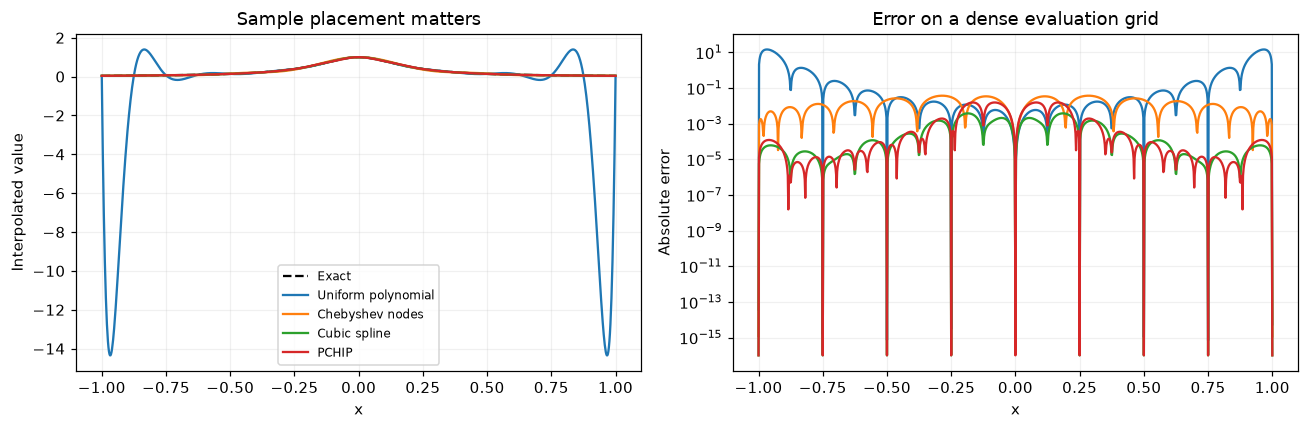

Uniform polynomial    14.386268
Chebyshev nodes        0.036709
Cubic spline           0.003744
PCHIP                  0.015319
Name: Maximum sampled error, dtype: float64

In [10]:
runge = lambda x: 1 / (1 + 25 * x * x)
x_uniform = cx.linspace(-1.0, 1.0, 17)
x_cheb = np.sort(np.cos(np.pi * np.arange(17) / 16))
query = cx.linspace(-1.0, 1.0, 1001)
curves = {'Uniform polynomial': cx.polynomial_approximation(x_uniform, runge(x_uniform), 16), 'Chebyshev nodes': cx.polynomial_approximation(x_cheb, runge(x_cheb), 16), 'Cubic spline': cx.spline(x_uniform, runge(x_uniform)), 'PCHIP': cx.interpolate(x_uniform, runge(x_uniform), tool=cx.Interpolation('pchip'))}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(query, runge(query), 'k--', label='Exact')
errors = {}
for name, curve in curves.items():
    values = curve(query)
    errors[name] = np.max(np.abs(values - runge(query)))
    axes[0].plot(query, values, label=name)
    axes[1].semilogy(query, np.maximum(np.abs(values - runge(query)), 1e-16), label=name)
axes[0].set(xlabel='x', ylabel='Interpolated value', title='Sample placement matters')
axes[1].set(xlabel='x', ylabel='Absolute error', title='Error on a dense evaluation grid')
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()
display(pd.Series(errors, name='Maximum sampled error'))

## Matrix functions and equations describe coupled dynamics

A matrix exponential evolves a linear system; it is not an elementwise exponential. The rotation generator below produces the familiar rotation matrix. A generalized eigenproblem uses a mass matrix to define orthogonality, and a Lyapunov equation describes how noise balances stable dynamics.

The continuous-time Lyapunov convention used here is $AX+XA^T+Q=0$. Its diagonal solution makes the role of the two decay rates visible.

In [11]:
K = np.array([[2., -1.], [-1., 2.]])
M = np.diag([1., 2.])
modes = cx.eigh(K, M)
display(pd.DataFrame({"generalized eigenvalue": modes.values, "angular frequency": np.sqrt(modes.values)}))
rotation = cx.expm(.7*np.array([[0., -1.], [1., 0.]])).value
display(pd.DataFrame(rotation, columns=["initial x", "initial y"], index=["rotated x", "rotated y"]))
stationary_covariance = cx.solve_lyapunov(np.diag([-1., -2.]), np.eye(2), time="continuous").value
display(pd.DataFrame(stationary_covariance, columns=["slow coordinate", "fast coordinate"]))
pd.DataFrame({"time convention": ["continuous", "discrete"], "scalar Riccati solution": [
    float(cx.solve_riccati([[1.]], [[1.]], [[1.]], [[1.]], time=time).value[0, 0])
    for time in ("continuous", "discrete")]})

,generalized eigenvalue,angular frequency
0,0.633975,0.796225
1,2.366025,1.538189


,initial x,initial y
rotated x,0.764842,-0.644218
rotated y,0.644218,0.764842


,slow coordinate,fast coordinate
0,0.5,0.00
1,0.0,0.25


,time convention,scalar Riccati solution
0,continuous,2.414214
1,discrete,1.618034


## Sparse and matrix-free descriptions of the same operator

The tridiagonal operator can be stored sparsely or supplied as a matrix-vector function. We solve the same system through both routes. Conjugate gradients uses symmetry and positive definiteness; GMRES supports a broader operator class.

Iteration counts and residuals help inspect the solve. This small demonstration is not a timing benchmark, and its simple scaling preconditioner should not be mistaken for a general remedy for ill-conditioning.

In [12]:
n = 200
indices = np.arange(n)
rows = np.r_[indices, indices[:-1], indices[1:]]
cols = np.r_[indices, indices[1:], indices[:-1]]
data = np.r_[np.full(n, 3.0), -np.ones(n - 1), -np.ones(n - 1)]
sparse_A = cx.sparse_matrix((data, (rows, cols)), shape=(n, n))

def matvec(v):
    out = 3 * v.copy()
    out[:-1] -= v[1:]
    out[1:] -= v[:-1]
    return out
operator = cx.linear_operator((n, n), matvec, rmatvec=matvec)
preconditioner = cx.linear_operator((n, n), lambda v: v / 3, rmatvec=lambda v: v / 3)
sparse_exact = np.sin(np.pi * (indices + 1) / (n + 1)) + 0.2 * np.cos(0.17 * indices)
sparse_rhs = matvec(sparse_exact)
solver_rows = []
for name, matrix, tool in [('sparse direct', sparse_A, cx.SparseSolve()), ('matrix-free CG', operator, cx.SparseSolve(method='cg', preconditioner=preconditioner)), ('matrix-free GMRES', operator, cx.SparseSolve(method='gmres'))]:
    result = cx.solve(matrix, sparse_rhs, tool=tool)
    error = np.max(np.abs(result.value - sparse_exact))
    solver_rows.append({'method': name, 'max solution error': error, 'iterations': result.diagnostics.iterations, 'residual': result.diagnostics.residual_norm})
display(pd.DataFrame(solver_rows))

,method,max solution error,iterations,residual
0,sparse direct,2.220446e-16,NaN,2.482466e-15
1,matrix-free CG,2.156370e-10,22.0,8.087991e-10
2,matrix-free GMRES,6.498546e-11,23.0,4.000272e-10


## Differential equations: trajectory, events, and stiffness

The harmonic oscillator has a known orbit and zero-crossing times. `solve_ode` returns a continuous solution between requested outputs and event locations found by the solver.

The second equation has solution $\cos t$ but a fast transient timescale $10^{-3}$. Comparing RK45 and Radau at the same tolerances reveals the cost of stability restrictions in an explicit solver. Function evaluations are informative here; wall-clock performance depends on the problem and implementation.

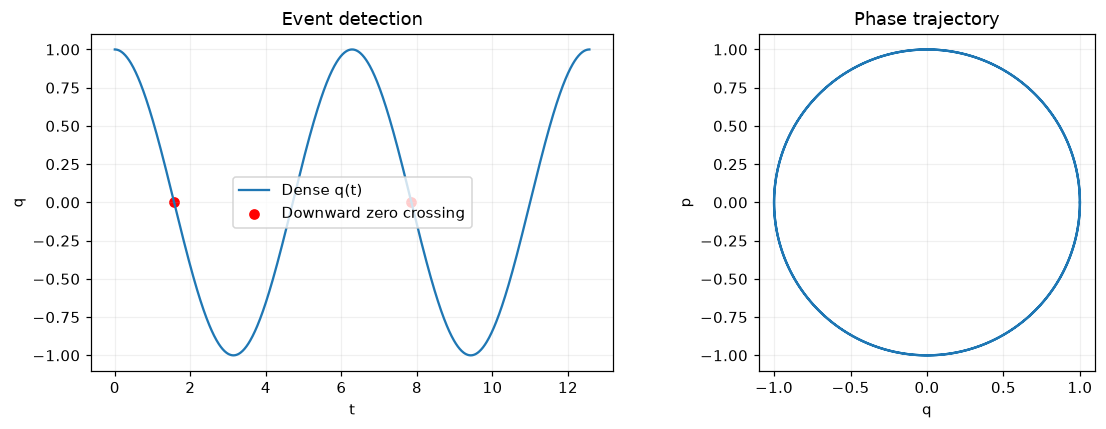

In [13]:
times = cx.linspace(0.0, 4 * np.pi, 160)
event = cx.ODEEvent(lambda t, y: y[0], direction=-1)
oscillator = cx.solve_ode(lambda t, y: np.array([y[1], -y[0]]), [1.0, 0.0], times, events=(event,), tool=cx.IVPSolver(method='DOP853', rtol=1e-09, atol=1e-11, max_step=0.2))
fine_t = cx.linspace(0.0, 4 * np.pi, 1000)
dense = oscillator.solution(fine_t)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(fine_t, dense[0], label='Dense q(t)')
axes[0].scatter(oscillator.events[0].t, np.zeros(2), color='red', label='Downward zero crossing')
axes[0].set(xlabel='t', ylabel='q', title='Event detection')
axes[0].legend()
axes[1].plot(dense[0], dense[1])
axes[1].set(xlabel='q', ylabel='p', title='Phase trajectory', aspect='equal')
plt.tight_layout()
plt.show()

In [14]:
stiff_rhs = lambda t, y: -1000 * (y - np.cos(t)) - np.sin(t)
stiff_t = cx.linspace(0.0, 2.0, 201)
stiff_rows = []
for method in ('RK45', 'Radau'):
    result = cx.solve_ode(stiff_rhs, [1.0], stiff_t, tool=cx.IVPSolver(method=method, atol=1e-09, rtol=1e-07), jacobian=(lambda t, y: np.array([[-1000.0]])) if method == 'Radau' else None)
    error = np.max(np.abs(result.y[0] - np.cos(stiff_t)))
    stiff_rows.append({'method': method, 'RHS evaluations': result.diagnostics.evaluations, 'max solution error': error})
display(pd.DataFrame(stiff_rows))

,method,RHS evaluations,max solution error
0,RK45,5900,5.299361e-08
1,Radau,113,8.100867e-07


## Boundary values and mesh refinement

The BVP solves $u''=-\pi^2\sin(\pi x)$ with zero endpoint values. Its exact solution makes the adaptive mesh and interior interpolation error inspectable. The BVP callback receives all mesh coordinates together, unlike a single-time IVP callback.

Finally, a fourth-order periodic differentiation matrix approximates the derivative of $\sin x$. Halving the spacing should reduce truncation error by roughly sixteen before roundoff dominates. The table reports the order observed between successive resolutions.

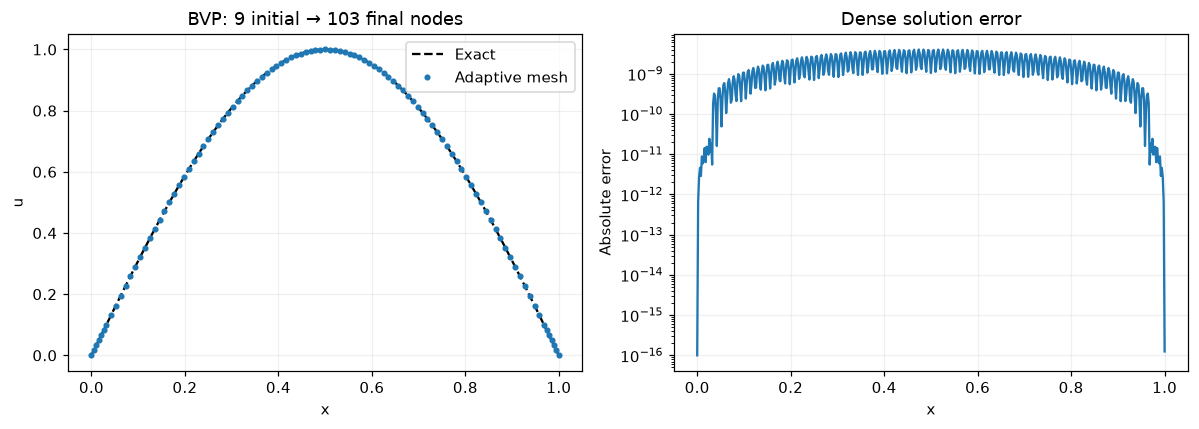

In [15]:
bvp_x = cx.linspace(0.0, 1.0, 9)

def bvp_rhs(x, y):
    return np.vstack((y[1], -np.pi ** 2 * np.sin(np.pi * x)))
boundary = lambda left, right: np.array([left[0], right[0]])
bvp = cx.solve_bvp(bvp_rhs, boundary, bvp_x, np.zeros((2, len(bvp_x))))
eval_x = cx.linspace(0.0, 1.0, 501)
bvp_values = bvp.solution(eval_x)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(eval_x, np.sin(np.pi * eval_x), 'k--', label='Exact')
axes[0].plot(bvp.x, bvp.y[0], '.', label='Adaptive mesh')
axes[0].set(xlabel='x', ylabel='u', title=f'BVP: {len(bvp_x)} initial → {len(bvp.x)} final nodes')
axes[0].legend()
axes[1].semilogy(eval_x, np.maximum(np.abs(bvp_values[0] - np.sin(np.pi * eval_x)), 1e-16))
axes[1].set(xlabel='x', ylabel='Absolute error', title='Dense solution error')
plt.tight_layout()
plt.show()

,nodes,h,max error,observed order
0,16,0.392699,7.782942e-04,NaN
1,32,0.196350,4.931794e-05,3.980131
2,64,0.098175,3.093001e-06,3.995034
3,128,0.049087,1.934790e-07,3.998758


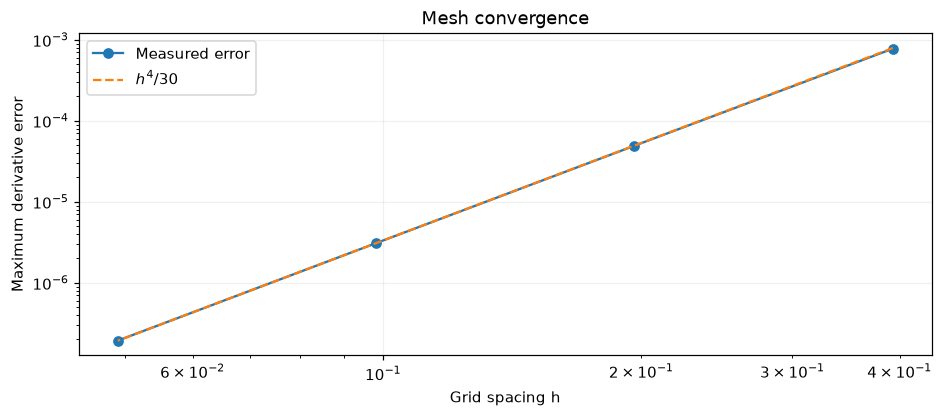

In [16]:
refinement = []
for count in (16, 32, 64, 128):
    grid = cx.linspace(0.0, 2 * np.pi, count, endpoint=False)
    D = cx.differentiation_matrix(grid, order=1, accuracy=4, periodic=True)
    error = np.max(np.abs(D @ np.sin(grid) - np.cos(grid)))
    refinement.append({'nodes': count, 'h': 2 * np.pi / count, 'max error': error})
refinement = pd.DataFrame(refinement)
refinement['observed order'] = np.log2(refinement['max error'].shift(1) / refinement['max error'])
display(refinement)
plt.loglog(refinement['h'], refinement['max error'], 'o-', label='Measured error')
plt.loglog(refinement['h'], refinement['h'] ** 4 / 30, '--', label='$h^4/30$')
plt.xlabel('Grid spacing h')
plt.ylabel('Maximum derivative error')
plt.title('Mesh convergence')
plt.legend()
plt.show()

Try a higher-frequency function, fewer initial BVP nodes, or tighter IVP tolerances. Keep both computational effort and error visible. The [full numerical catalog](../numerical_mathematics.md) includes multidimensional operators, backend selection, and custom tool contracts beyond the worked comparisons here.